# Output against a clear sky

The solar label is settled ([notebook 08](08_solar_label.ipynb)): delivered output with curtailed output added back. Before any feature or model, this notebook asks one question: **how does real output compare with what a cloudless sky would give, and is that relationship steady enough to forecast with?**

*Clear-sky output* is what the fleet would produce as flat panels under a cloudless sky ([notebook 05](05_clear_sky.ipynb)): capacity times a clear-sky radiation that depends only on where the sun stands. Dividing output by it takes out the sun's path through the day and the year. What is left is the weather and whatever the flat-panel picture gets wrong.

| Uncertainty | We assumed | Where |
| --- | --- | --- |
| How the ratio changes through the day and the year on clear days | Far from flat: low at dawn and dusk, above 1 at midday in winter | Sections 1 and 2 |
| Whether the clear-day ratio holds from 2024 to 2026 | Roughly steady | Sections 3 and 8 |
| Whether a model should predict MW, with capacity growing | A tree can't predict above what it trained on, so MW would clip | Section 4 |
| How well the last week's ratio predicts the next day | Better than the same slot two days back | Section 5 |
| Where clear ends and cloudy begins | Days fall into two loose groups | Section 6 |
| Whether forecast radiation is in step with the sun | It is, to the slot | Section 7 |

The steps are in the order they were taken. Two of them answered a question that turned out to be the wrong one (sections 3 and 4), and one finding was not looked for (section 5).

## 0. Setup

**Step.** `sql()` runs a query in the dev project and prints what it scanned. `SLOTS` is every labelled slot of a target day, with clear-sky output and capacity as DWS knew them at that day's decision time. A slot is **lit** when clear sky allows at least 5% of capacity (notebook 08): the ratio of output to clear sky is read only there, since at dawn and dusk it divides by almost nothing. `grid()` lays a column out as one row per day and one column per slot.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.3f}".format)


def setting(name: str) -> str:
    if value := os.environ.get(name):
        return value
    lines = Path("../.env").read_text().splitlines()
    env = dict(line.split("=", 1) for line in lines if "=" in line and not line.startswith("#"))
    return env[name]


PROJECT = setting("JTF_BIGQUERY_PROJECT")
PREFIX = setting("JTF_DBT_DATASET_PREFIX")
ADS, DWS, DWD, DIM = (f"{PROJECT}.{PREFIX}_{layer}" for layer in ("ads", "dws", "dwd", "dim"))
bq = bigquery.Client(project=PROJECT, location=setting("JTF_BIGQUERY_LOCATION"))


def sql(query: str) -> pd.DataFrame:
    """Run a query in the dev project; print what it scanned and how long it took."""
    job = bq.query(query, job_config=bigquery.QueryJobConfig(use_query_cache=False))
    rows = job.to_dataframe(create_bqstorage_client=False)
    seconds = (job.ended - job.started).total_seconds()
    print(f"[{(job.total_bytes_processed or 0) / 1e6:.1f} MB scanned, {seconds:.0f} s in BigQuery]")
    return rows


# Every labelled slot of a target day, with what DWS knew of it at its decision time. A slot is
# "lit" when clear sky allows at least 5% of capacity (notebook 08): ratios are read only there.
SLOTS = f"""
SELECT l.slot_start, f.target_day AS day,
  FORMAT_TIMESTAMP('%H:%M', l.slot_start, 'Asia/Tokyo') AS slot,
  l.label_mw, f.clear_sky_mw, f.capacity_mw, NOT n.is_night AS is_daylight,
  f.clear_sky_mw >= 0.05 * f.capacity_mw AS is_lit
FROM `{ADS}.ads_ml_label_solar` AS l
INNER JOIN `{DWS}.dws_solar_features` AS f USING (slot_start)
INNER JOIN `{DIM}.dim_daylight` AS n USING (slot_start)
"""

slots = sql(f"{SLOTS} ORDER BY slot_start")
slots["day"] = pd.to_datetime(slots["day"])
slots["ratio"] = (slots["label_mw"] / slots["clear_sky_mw"]).where(slots["is_lit"].astype(bool))
print(
    f"{len(slots):,} slots on {slots['day'].nunique():,} days, {slots['day'].min():%Y-%m-%d} to "
    f"{slots['day'].max():%Y-%m-%d}; {int(slots['is_lit'].sum()):,} lit"
)


def grid(column: str) -> pd.DataFrame:
    """One row per day, one column per slot of the day."""
    return slots.pivot(index="day", columns="slot", values=column).asfreq("D")


RATIO, LABEL, CLEAR_SKY = grid("ratio"), grid("label_mw"), grid("clear_sky_mw")
CAPACITY = slots.groupby("day")["capacity_mw"].first().asfreq("D")
hours = np.arange(48) / 2

[4.7 MB scanned, 1 s in BigQuery]
48,305 slots on 1,007 days, 2024-02-17 to 2026-11-19; 22,854 lit


**What it shows.** 48,305 slots on 1,007 target days, from 17 February 2024 to 19 November 2026; 22,854 are lit.

## 1. A first look: four clear days

**Step.** The clearest day of January, April, July and October 2025, each picked by its output over its clear-sky output across the lit slots (the *day ratio*). Left, output over capacity; right, the ratio slot by slot.

,day_ratio,peak_over_capacity,ratio_at_08:00,ratio_at_12:00,ratio_at_15:00
day,,,,,
2025-01-11,1.139,0.623,0.895,1.197,1.098
2025-04-09,0.826,0.813,0.782,0.895,0.803
2025-07-29,0.694,0.743,0.682,0.755,0.694
2025-10-30,0.973,0.670,0.780,1.066,0.969


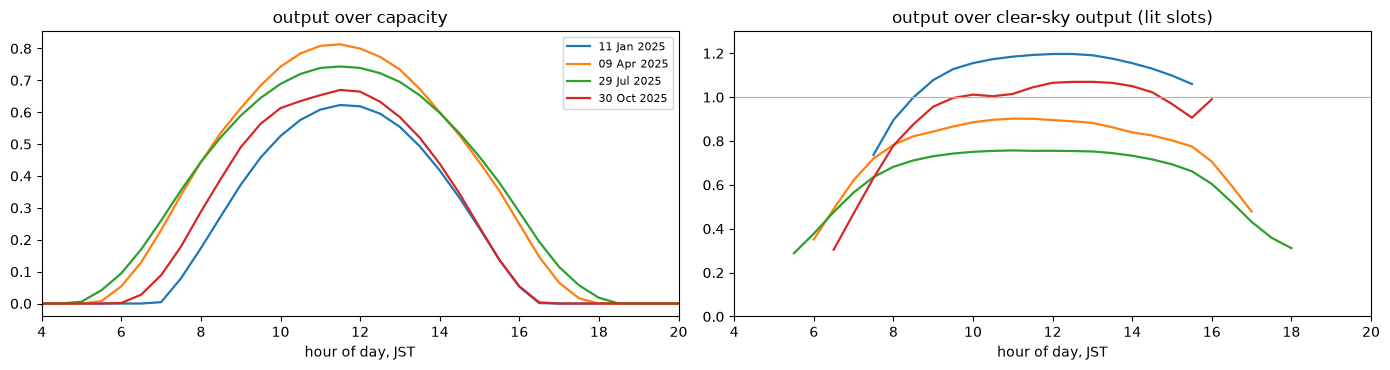

In [2]:
by_day = LABEL.where(RATIO.notna()).sum(axis=1) / CLEAR_SKY.where(RATIO.notna()).sum(axis=1)
by_day = by_day[RATIO.notna().sum(axis=1) >= 8]  # the day's output over its clear-sky output
picked = pd.to_datetime(
    [
        by_day[(by_day.index.year == 2025) & (by_day.index.month == month)].idxmax()
        for month in (1, 4, 7, 10)
    ]
)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for day in picked:
    label = f"{day:%d %b %Y}"
    axes[0].plot(hours, LABEL.loc[day].to_numpy() / CAPACITY.loc[day], lw=1.6, label=label)
    axes[1].plot(hours, RATIO.loc[day].to_numpy(), lw=1.6, label=label)
axes[0].set(title="output over capacity", xlim=(4, 20), xlabel="hour of day, JST")
axes[1].set(
    title="output over clear-sky output (lit slots)",
    xlim=(4, 20),
    ylim=(0, 1.3),
    xlabel="hour of day, JST",
)
axes[1].axhline(1, color="0.7", lw=0.8)
axes[0].legend(fontsize=8)
fig.tight_layout()
pd.DataFrame(
    {
        "day_ratio": by_day.loc[picked],
        "peak_over_capacity": (LABEL.loc[picked].max(axis=1) / CAPACITY.loc[picked]),
        "ratio_at_08:00": RATIO.loc[picked, "08:00"],
        "ratio_at_12:00": RATIO.loc[picked, "12:00"],
        "ratio_at_15:00": RATIO.loc[picked, "15:00"],
    }
).rename(index=lambda day: f"{day:%Y-%m-%d}")

**What it shows.** **Observed:**

- **The ratio is nowhere near 1, and not the same in any two seasons.** At noon it is 1.20 on the January day, 0.90 in April, 0.76 in July and 1.07 in October
- **It bends through the day:** on the January day it climbs from 0.90 at 08:00 to 1.20 at noon; in July from 0.68 to 0.76
- **The fleet never comes near its nameplate:** the best slot of the four days is 0.81 of capacity, in April. January's clear day peaks at 0.62 of capacity while its ratio is the highest

**Learned → design:** flat-panel clear sky is a rough yardstick: winter output runs a fifth above it and summer output a quarter below. Four days prove nothing about the year, so the next step takes every day.

## 2. A clear day's ratio, through the day and the year

**Step.** For each slot and each day, what a clear day gives at that time of year: the 90th percentile of the same slot's ratio over the 29 days around it, as in notebook 08. Averaged by month, for ten slots of the day, and drawn for all of them.

In [3]:
WINDOW, ENOUGH = 29, 8  # a day's neighbours: 14 days either side, at least 8 of them


def nearby(days: pd.DataFrame):
    """A rolling view of the days around each day."""
    return days.rolling(WINDOW, center=True, min_periods=ENOUGH)


# What a clear day gives in each slot at that time of year: the 90th percentile of the same slot
# on the days nearby (notebook 08, section 3.4)
CLEAR = nearby(RATIO).quantile(0.9)
shown = ["06:00", "07:00", "08:00", "09:00", "10:00", "12:00", "14:00", "15:00", "16:00", "17:00"]
by_month = CLEAR.groupby(CLEAR.index.month).mean()[shown].rename_axis("month")
by_month.round(2)

slot,06:00,07:00,08:00,09:00,10:00,12:00,14:00,15:00,16:00,17:00
month,,,,,,,,,,
1,NaN,0.410,0.910,1.080,1.150,1.190,1.180,1.110,1.070,NaN
2,NaN,0.530,0.870,1.030,1.090,1.110,1.100,1.050,0.900,NaN
3,0.270,0.590,0.830,0.960,1.000,1.020,1.000,0.950,0.790,0.590
4,0.380,0.630,0.790,0.860,0.880,0.890,0.860,0.810,0.680,0.470
5,0.420,0.620,0.740,0.790,0.820,0.820,0.790,0.750,0.640,0.450
6,0.410,0.580,0.690,0.740,0.760,0.760,0.730,0.680,0.590,0.430
7,0.360,0.530,0.630,0.690,0.710,0.720,0.680,0.640,0.560,0.420
8,0.340,0.530,0.640,0.700,0.720,0.720,0.700,0.660,0.570,0.410
9,0.300,0.550,0.690,0.740,0.770,0.790,0.750,0.700,0.590,0.410


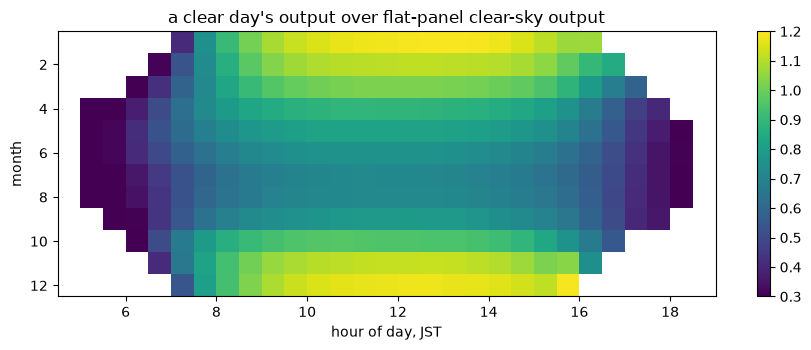

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
image = ax.imshow(
    CLEAR.groupby(CLEAR.index.month).mean().to_numpy(),
    aspect="auto",
    cmap="viridis",
    extent=(0, 24, 12.5, 0.5),
    vmin=0.3,
    vmax=1.2,
)
ax.set(
    xlim=(4.5, 19),
    xlabel="hour of day, JST",
    ylabel="month",
    title="a clear day's output over flat-panel clear-sky output",
)
fig.colorbar(image, ax=ax)
fig.tight_layout()

**What it shows.** **Observed:**

- **Midday swings with the season, from 0.72 to 1.19.** A clear noon gives 1.19 times flat-panel clear sky in January and 0.72 in July and August
- **Morning and evening sit far below midday all year:** at 07:00, 0.41 in January and 0.53 in July
- **The day is not symmetric:** the afternoon holds up longer than the morning builds (in January, 1.11 at 15:00 against 0.91 at 08:00)

Tilted panels are the likely reason for winter: they face a low sun more squarely than flat ones, which is the error notebook 05 expected. Summer's low ratio has several candidates this notebook can't tell apart: hot panels, humid air that the clear-sky formula knows nothing of, panels tilted away from a high sun.

**Learned → design:** clear-sky output can't stand in for "what a clear day produces" without the hour and the season beside it. A model that reads it needs both.

**In one picture.** The same clear-day ratio for January and July, hour by hour, against the line an exact yardstick would give:

![Clear-sky output is a rough yardstick: on clear days, output over clear-sky output by hour, for January and July](../docs/assets/clear-sky-yardstick.svg)

**Step.** Does it matter for a forecast? The plan's simple baseline multiplies clear-sky output by one recent ratio. The kindest test of one ratio per day: on the clearest days (those within 5% of a clear day's level for their time of year), give every slot the day's own ratio, known only in hindsight, and see what is still missed, by slot and season.

In [5]:
# The clearest days: those whose own ratio is within 5% of a clear day's at their time of year
clear_day = by_day / nearby(by_day.to_frame("r"))["r"].quantile(0.9)
clearest = clear_day[clear_day >= 0.95].index
lit = RATIO.loc[clearest].notna()
one_ratio = CLEAR_SKY.loc[clearest].mul(by_day.loc[clearest], axis=0)  # the day's own ratio
miss = (one_ratio - LABEL.loc[clearest]).where(lit).div(CAPACITY.loc[clearest], axis=0)
print(
    f"{len(clearest)} clear days of {len(by_day)}; with the day's own ratio on every slot: "
    f"mean absolute miss {miss.abs().stack().mean():.3f} of capacity, "
    f"largest {miss.abs().stack().max():.3f}"
)
season = pd.Series(
    clearest.month.map(
        lambda m: (
            "Nov to Feb"
            if m in (11, 12, 1, 2)
            else "May to Aug"
            if m in (5, 6, 7, 8)
            else "spring, autumn"
        )
    ),
    index=clearest,
)
miss.groupby(season).mean()[shown].round(3)

291 clear days of 1006; with the day's own ratio on every slot: mean absolute miss 0.040 of capacity, largest 0.161


slot,06:00,07:00,08:00,09:00,10:00,12:00,14:00,15:00,16:00,17:00
day,,,,,,,,,,
May to Aug,0.083,0.061,0.010,-0.032,-0.058,-0.070,-0.029,0.007,0.049,0.066
Nov to Feb,NaN,0.053,0.048,0.012,-0.016,-0.030,-0.010,0.009,0.022,NaN
"spring, autumn",0.060,0.073,0.030,-0.013,-0.042,-0.053,-0.019,0.013,0.046,0.039


**What it shows.** **Observed**, on 291 clear days:

- **Even the day's own ratio misses by 4.0% of capacity on average,** and by 16.1% in the worst slot
- **The miss has a shape:** too high in the morning and evening (by 6 to 8% of capacity at 06:00 and 07:00 in summer), too low at midday (by 7% at noon in summer)

**Learned → design:** if a ratio is used, it is one per slot, not one per day. Section 5 tests that on forecasts, not in hindsight.

## 3. Does the ratio hold from year to year?

**Step.** If the fleet or its capacity estimate drifted, a clear midday would give a different ratio in the same month of different years. A clear midday's ratio (the mean of the clear-day level over 10:00 to 14:00) by month and year, and each year over the one before.

In [6]:
midday = [f"{hour:02d}:{minute:02d}" for hour in range(10, 14) for minute in (0, 30)]
level = CLEAR[midday].mean(axis=1).dropna()
by_year = level.groupby([level.index.year, level.index.month]).mean().unstack(0)
by_year.columns = by_year.columns.astype(str)
by_year["2025_over_2024"] = by_year["2025"] / by_year["2024"]
by_year["2026_over_2025"] = by_year["2026"] / by_year["2025"]
display(by_year.rename_axis("month").round(3))
change = by_year[["2025_over_2024", "2026_over_2025"]]
print(
    f"a clear midday's ratio, year on year: mean {change.stack().mean():.3f}, "
    f"from {change.stack().min():.3f} to {change.stack().max():.3f} over "
    f"{change.stack().count()} month pairs; standard deviation {change.stack().std():.3f}"
)

day,2024,2025,2026,2025_over_2024,2026_over_2025
month,,,,,
1,NaN,1.171,1.187,NaN,1.014
2,1.038,1.119,1.127,1.078,1.007
3,1.012,1.028,1.012,1.016,0.984
4,0.881,0.876,0.897,0.994,1.024
5,0.843,0.786,0.822,0.933,1.045
6,0.823,0.726,0.721,0.882,0.993
7,0.713,0.734,0.698,1.030,0.951
8,0.706,0.763,0.691,1.080,0.905
9,0.777,0.811,0.757,1.044,0.933


a clear midday's ratio, year on year: mean 0.995, from 0.882 to 1.084 over 22 month pairs; standard deviation 0.055


**What it shows.** **Observed:**

- **On average, no drift:** 0.995 over 22 pairs of the same month a year apart
- **Month by month it jumps about:** from 0.88 (June 2025 against June 2024) to 1.08 (August 2025 against 2024, October 2026 against 2025), with a standard deviation of 0.055

A fleet doesn't lose 12% in one June and gain 8% the next August. The yardstick is the suspect: "the 90th percentile of 29 days" is a clear day only where the 29 days hold a few clear ones, and in the rainy season they may hold none. So the month-level numbers measure how cloudy each month was as much as what a clear day gives.

**Learned → design:** the mean says steady, to about one percent a year (0.055 over the square root of 22). The months can't be read one by one this way. Section 8 tries again with clear days picked by the weather forecast, once it is loaded.

## 4. Would a model predicting MW run out of range?

**Step.** A tree model can't predict above the largest value it was trained on, and capacity grows every quarter. Per year: capacity at its start and end, the highest slot, and how much of 2026 lies above everything in 2024 and 2025.

In [7]:
yearly = pd.DataFrame(
    {
        "capacity_mw_first": CAPACITY.groupby(CAPACITY.index.year).first(),
        "capacity_mw_last": CAPACITY.groupby(CAPACITY.index.year).last(),
        "highest_slot_mw": LABEL.max(axis=1).groupby(LABEL.index.year).max(),
        "highest_over_capacity": (LABEL.max(axis=1) / CAPACITY).groupby(LABEL.index.year).max(),
        "highest_ratio": RATIO.max(axis=1).groupby(RATIO.index.year).max(),
    }
).rename_axis("year")
display(yearly)
before = LABEL[LABEL.index.year < 2026]
later = LABEL[LABEL.index.year == 2026]
above = later > before.max().max()
print(
    f"2026: {int(above.sum().sum())} slots on {int(above.any(axis=1).sum())} days above every "
    f"slot of 2024 and 2025 ({before.max().max():,.0f} MW); the highest by "
    f"{later.max().max() - before.max().max():,.0f} MW"
)
ratio_2026 = RATIO[RATIO.index.year == 2026]
above_ratio = ratio_2026 > RATIO[RATIO.index.year < 2026].max()
print(
    f"as ratios, slot by slot of the day: {int(above_ratio.sum().sum())} slots of 2026 above "
    f"every earlier value of the same slot, of {int(ratio_2026.notna().sum().sum())}"
)

,capacity_mw_first,capacity_mw_last,highest_slot_mw,highest_over_capacity,highest_ratio
year,,,,,
2024,"19,346.280","19,703.338","16,655.000",0.861,1.234
2025,"19,705.390","20,450.032","16,697.000",0.841,1.238
2026,"20,452.118","21,041.284","17,840.000",0.866,1.222


2026: 40 slots on 14 days above every slot of 2024 and 2025 (16,697 MW); the highest by 1,143 MW
as ratios, slot by slot of the day: 14 slots of 2026 above every earlier value of the same slot, of 7397


**What it shows.** **Observed:**

- **Capacity grew by 8.8%,** from 19,346 MW in February 2024 to 21,041 MW in November 2026
- **The year's highest slot follows it:** 16,655, 16,697 and 17,840 MW, each close to 0.85 of capacity
- **40 slots on 14 days of 2026 lie above everything in 2024 and 2025,** the highest by 1,143 MW. As ratios to clear sky, slot by slot of the day, 14 of 2026's 7,397 lit slots are above every earlier value

That looks like a real problem for MW. But it is the wrong comparison: no model in this project is trained on two years and then left alone for a third. The backtest retrains every month ([plan](../docs/phase1/README.md#decisions), "Backtest retraining cadence").

**Step.** The same question for a model retrained at the start of each month: how many slots lie above everything before their own month?

In [8]:
# What a model retrained at the start of each month has seen: every day before that month
day_max = LABEL.max(axis=1)
month_start = day_max.index.to_period("M").start_time
seen_before = day_max.cummax().shift(1).groupby(month_start).first().reindex(month_start).to_numpy()
over = LABEL.sub(seen_before, axis=0).loc["2025-03-01":]
clipped = over.where(over > 0)
print(
    f"from March 2025: {int(clipped.notna().sum().sum())} slots on "
    f"{int(clipped.notna().any(axis=1).sum())} days above everything seen before their month; "
    f"largest {clipped.max().max():,.0f} MW, {clipped.max().max() / CAPACITY.max():.3f} of capacity"
)
by_month = clipped.notna().sum(axis=1).groupby(clipped.index.to_period("M")).sum()
by_month[by_month > 0].to_frame("slots_above_everything_seen").T

from March 2025: 23 slots on 8 days above everything seen before their month; largest 720 MW, 0.034 of capacity


day,2025-03,2026-03,2026-04
slots_above_everything_seen,2,10,11


**What it shows.** **Observed**, from March 2025:

- **23 slots on 8 days,** against 40 on 14: 2 in March 2025, 10 in March 2026, 11 in April 2026
- **The largest is 720 MW above everything seen, 3.4% of capacity**
- **They come in spring,** when the year's peak passes the last one

**Learned → design:** with monthly retraining the clipping is small, and it falls on the best days of the year, where a forecast is worth most. Predicting output over capacity removes it at no cost, since capacity at `T` is already a feature. Whether to divide by capacity or by clear-sky output is a modelling choice for the backtest: dividing by clear sky also removes the day's shape, but near dawn and dusk it divides by little.

## 5. How well does the last week predict the next day?

**Step.** The baseline candidates need the past days' output as it was known at each decision time `T` (09:00 on the day before the target day), not as it is known now. So the read goes through `as_of`, the way dbt will run it: for each target slot, the same slot 2 to 15 days back, at the version current at `T`, delivered and curtailed added. The newest complete day at `T` is two days back ([notebook 04](04_ods_to_dwd.ipynb), section 5.3). `shape` is clear-sky output per MW of capacity: the sun's part alone.

In [9]:
FIRST, LAST = "2025-03-01", "2026-10-31"  # the persistence backtest's target days
AS_OF = (
    "a.known_at <= s.decision_time AND (a.known_until IS NULL OR s.decision_time < a.known_until)"
)
past = sql(f"""
WITH spine AS (
  SELECT decision_time, slot_start FROM `{DWS}.dws_decision_slots`
  WHERE target_day BETWEEN '{FIRST}' AND '{LAST}'
),
shapes AS (  -- clear-sky output per MW of capacity: the sun's part, with no capacity in it
  SELECT slot_start, SAFE_DIVIDE(clear_sky_mw, capacity_mw) AS shape
  FROM `{DWS}.dws_solar_features`
)
SELECT s.decision_time, s.slot_start, days_back, SUM(a.value_mw) AS output_mw,
  ANY_VALUE(p.shape) AS shape, COUNT(*) AS measures
FROM spine AS s
CROSS JOIN UNNEST(GENERATE_ARRAY(2, 15)) AS days_back
INNER JOIN `{DWD}.dwd_tepco_actuals` AS a
  ON a.slot_start = TIMESTAMP_SUB(s.slot_start, INTERVAL days_back DAY)
  AND a.measure IN ('solar', 'solar_curtailed') AND {AS_OF}
INNER JOIN shapes AS p ON p.slot_start = a.slot_start
GROUP BY s.decision_time, s.slot_start, days_back
""")
target = (
    sql(f"""
SELECT f.decision_time, f.target_day, f.slot_start, f.capacity_mw,
  SAFE_DIVIDE(f.clear_sky_mw, f.capacity_mw) AS shape, f.solar_d2_mw, l.label_mw,
  NOT n.is_night AS is_daylight
FROM `{DWS}.dws_solar_features` AS f
INNER JOIN `{ADS}.ads_ml_label_solar` AS l USING (slot_start)
INNER JOIN `{DIM}.dim_daylight` AS n USING (slot_start)
WHERE f.target_day BETWEEN '{FIRST}' AND '{LAST}'
""")
    .set_index(["decision_time", "slot_start"])
    .sort_index()
)
print(
    f"{len(target):,} target slots; {len(past):,} past slots known at their decision times, "
    f"{int((past['measures'] != 2).sum())} without both measures; "
    f"{past.groupby(['decision_time', 'slot_start']).size().eq(14).mean():.3f} of target slots "
    f"with all 14 days back"
)

[7.3 MB scanned, 1 s in BigQuery]


[5.4 MB scanned, 0 s in BigQuery]
29,280 target slots; 409,920 past slots known at their decision times, 0 without both measures; 1.000 of target slots with all 14 days back


**What it shows.** 29,280 target slots over the persistence backtest's target days, March 2025 to October 2026, and 409,920 past slots as known at their decision times. Every one has both measures, and every target slot has all 14 days back.

**Step.** The candidates, each a prediction for every target slot:

- **Persistence:** the same slot two days back, as built (delivered output), and with curtailed output added
- **Day ratio:** clear sky on the target slot times the median, over the last 7 complete days, of each day's ratio
- **Slot ratio:** the same with each past day's ratio in the same slot: the median or the mean of 7 days, the median of 3 and of 14, and the single day two days back
- **No clear sky at all:** the mean and the median of the same slot's output over the last 7 days

The last two were added after the first run of this cell: the slot ratio from two days back had scored the same as persistence, which raised the question of what clear sky was adding. Scored as the backtest scores: mean absolute error on daylight slots as a share of capacity at `T`; skill is 1 minus the error over persistence's.

In [10]:
LIT = 0.05
output = past.pivot(index=["decision_time", "slot_start"], columns="days_back", values="output_mw")
shape = past.pivot(index=["decision_time", "slot_start"], columns="days_back", values="shape")
output, shape = output.reindex(target.index), shape.reindex(target.index)
per_slot = (output / shape).where(shape >= LIT)  # each past day's ratio in the same slot
times = target.index.get_level_values("decision_time")
per_day = (  # each past day's ratio over its lit slots, the same for every slot of the target day
    output.where(shape >= LIT).groupby(times).transform("sum")
    / shape.where(shape >= LIT).groupby(times).transform("sum")
)


def predict(ratios: pd.DataFrame, days: range, how: str) -> pd.Series:
    """Clear sky on the target slot x the past days' typical ratio; in slots too dim for a ratio,
    the past days' typical output."""
    typical = getattr(ratios[list(days)], how)(axis=1)
    dim = getattr(output[list(days)], how)(axis=1)
    return (target["shape"] * typical).where(target["shape"] >= LIT).fillna(dim)


CANDIDATES = {
    "persistence, 2 days back": target["solar_d2_mw"],
    "sum 2 days back": output[2],
    "day ratio, median of 7": predict(per_day, range(2, 9), "median"),
    "slot ratio, median of 7": predict(per_slot, range(2, 9), "median"),
    "slot ratio, mean of 7": predict(per_slot, range(2, 9), "mean"),
    "slot ratio, median of 3": predict(per_slot, range(2, 5), "median"),
    "slot ratio, median of 14": predict(per_slot, range(2, 16), "median"),
    "slot ratio, 2 days back": predict(per_slot, range(2, 3), "median"),
    "output, mean of 7": output[list(range(2, 9))].mean(axis=1),
    "output, median of 7": output[list(range(2, 9))].median(axis=1),
}
scored = target["is_daylight"].astype(bool) & target["label_mw"].notna()
error = pd.DataFrame(CANDIDATES).sub(target["label_mw"], axis=0).div(target["capacity_mw"], axis=0)
error = error[scored]
scores = pd.DataFrame(
    {
        "slots": error.notna().sum(),
        "mae": error.abs().mean(),
        "bias": error.mean(),
    }
)
scores["skill_over_persistence"] = 1 - scores["mae"] / scores["mae"].iloc[0]
scores

,slots,mae,bias,skill_over_persistence
"persistence, 2 days back",15935,0.124,-0.001,0.000
sum 2 days back,15935,0.125,0.001,-0.002
"day ratio, median of 7",15935,0.111,0.018,0.104
"slot ratio, median of 7",15935,0.106,0.019,0.149
"slot ratio, mean of 7",15935,0.103,0.002,0.174
"slot ratio, median of 3",15935,0.115,0.011,0.075
"slot ratio, median of 14",15935,0.104,0.026,0.165
"slot ratio, 2 days back",15935,0.125,0.001,-0.003
"output, mean of 7",15935,0.103,0.001,0.173
"output, median of 7",15935,0.106,0.018,0.149


In [11]:
fold = pd.Series(
    target.loc[error.index, "target_day"].astype("datetime64[ns]").dt.to_period("M"),
    index=error.index,
)
keep = [
    "persistence, 2 days back",
    "day ratio, median of 7",
    "slot ratio, median of 7",
    "slot ratio, mean of 7",
    "output, mean of 7",
]
by_fold = error[keep].abs().groupby(fold).mean()
wins = by_fold.lt(by_fold["persistence, 2 days back"], axis=0).sum()
print(f"folds where each beats persistence, of {len(by_fold)}:", wins.to_dict())
print(
    "folds where the slot ratio's mean of 7 beats its median of 7:",
    int((by_fold["slot ratio, mean of 7"] < by_fold["slot ratio, median of 7"]).sum()),
    "| beats the plain mean of 7 days' output:",
    int((by_fold["slot ratio, mean of 7"] < by_fold["output, mean of 7"]).sum()),
)
by_fold.T.round(3)

folds where each beats persistence, of 20: {'persistence, 2 days back': 0, 'day ratio, median of 7': 16, 'slot ratio, median of 7': 18, 'slot ratio, mean of 7': 20, 'output, mean of 7': 20}
folds where the slot ratio's mean of 7 beats its median of 7: 16 | beats the plain mean of 7 days' output: 10


target_day,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
"persistence, 2 days back",0.183,0.147,0.160,0.134,0.073,0.080,0.118,0.135,0.102,0.113,0.057,0.127,0.169,0.157,0.123,0.132,0.119,0.090,0.127,0.134
"day ratio, median of 7",0.161,0.151,0.122,0.131,0.093,0.089,0.095,0.115,0.076,0.083,0.045,0.120,0.129,0.133,0.126,0.129,0.106,0.090,0.087,0.124
"slot ratio, median of 7",0.154,0.149,0.116,0.130,0.076,0.080,0.090,0.115,0.073,0.080,0.039,0.118,0.122,0.128,0.113,0.124,0.096,0.084,0.087,0.125
"slot ratio, mean of 7",0.148,0.135,0.113,0.124,0.073,0.079,0.087,0.109,0.085,0.087,0.048,0.111,0.120,0.125,0.106,0.115,0.092,0.081,0.089,0.115
"output, mean of 7",0.147,0.135,0.113,0.124,0.073,0.079,0.087,0.111,0.082,0.086,0.053,0.112,0.121,0.125,0.107,0.115,0.092,0.082,0.091,0.115


**What it shows.** **Observed**, over 15,935 daylight slots in 20 monthly folds:

- **A week beats one day.** Persistence misses by 12.4% of capacity; the slot ratio's mean of 7 days by 10.3%, a skill of 0.17, and it wins in all 20 folds
- **A ratio per slot beats one per day,** 10.6% against 11.1% with the median, as section 2 suggested
- **The mean beats the median,** 10.3% against 10.6%, in 16 folds of 20, and without the median's bias (+0.2% against +1.9%). Most days are clear, so the middle day of seven is clearer than the average day
- **3 days are too few, and 14 no better than 7** (11.5% and 10.4%, the latter with a bias of +2.6%)
- **Clear sky adds nothing.** The plain mean of the same slot's output over 7 days scores 10.3% too, and the two split the folds 10 to 10. With one day, the slot ratio scores as persistence does (12.5% and 12.4%)

The last line was not looked for. The reason is simple once seen: the sun's path barely moves in a week, so dividing by clear sky and multiplying back changes almost nothing. What makes this baseline better than persistence is averaging over seven days, not the clear sky.

**Learned → design:** the baseline to beat is the mean of the same slot's output over the last seven complete days. "Clear sky × recent ratio" is the same forecast with two more steps, so it needs no place of its own beside it.

**Step.** The slot ratio's mean of 7 days once more, written in SQL the way a DWS model would compute it, and compared with the pandas candidate above. The plain mean of output comes out of the same query (`output_mean_7d`).

In [12]:
in_sql = (
    sql(f"""
WITH spine AS (
  SELECT s.decision_time, s.slot_start, SAFE_DIVIDE(f.clear_sky_mw, f.capacity_mw) AS shape
  FROM `{DWS}.dws_decision_slots` AS s
  INNER JOIN `{DWS}.dws_solar_features` AS f USING (decision_time, slot_start)
  WHERE s.target_day BETWEEN '{FIRST}' AND '{LAST}'
),
shapes AS (
  SELECT slot_start, SAFE_DIVIDE(clear_sky_mw, capacity_mw) AS shape
  FROM `{DWS}.dws_solar_features`
),
past AS (
  SELECT s.decision_time, s.slot_start, days_back, SUM(a.value_mw) AS output_mw,
    ANY_VALUE(p.shape) AS shape
  FROM spine AS s
  CROSS JOIN UNNEST(GENERATE_ARRAY(2, 8)) AS days_back
  INNER JOIN `{DWD}.dwd_tepco_actuals` AS a
    ON a.slot_start = TIMESTAMP_SUB(s.slot_start, INTERVAL days_back DAY)
    AND a.measure IN ('solar', 'solar_curtailed') AND {AS_OF}
  INNER JOIN shapes AS p ON p.slot_start = a.slot_start
  GROUP BY s.decision_time, s.slot_start, days_back
),
week AS (
  SELECT decision_time, slot_start, COUNT(*) AS days,
    AVG(IF(shape >= {LIT}, output_mw / shape, NULL)) AS ratio_mean_7d,
    AVG(output_mw) AS output_mean_7d
  FROM past GROUP BY decision_time, slot_start
)
SELECT s.decision_time, s.slot_start, w.days, w.ratio_mean_7d,
  IF(s.shape >= {LIT}, IFNULL(s.shape * w.ratio_mean_7d, w.output_mean_7d), w.output_mean_7d)
    AS predicted_mw
FROM spine AS s
INNER JOIN week AS w USING (decision_time, slot_start)
""")
    .set_index(["decision_time", "slot_start"])
    .sort_index()
)
apart = (in_sql["predicted_mw"] - CANDIDATES["slot ratio, mean of 7"]).abs()
print(
    f"{len(in_sql):,} slots in SQL, {int((in_sql['days'] != 7).sum())} without all 7 days; "
    f"largest difference from the pandas candidate: {apart.max():.2e} MW"
)

[7.7 MB scanned, 1 s in BigQuery]
29,280 slots in SQL, 0 without all 7 days; largest difference from the pandas candidate: 5.46e-12 MW


**What it shows.** The SQL gives the same prediction for all 29,280 slots, to within 5 × 10⁻¹² MW. The query moves into a model as it stands; its sums will need a fixed order there, since a float `SUM` varies with the order of addition.

## 6. Where clear ends and cloudy begins

**Step.** Accuracy is to be reported for clear and for cloudy days apart. A day's *clearness*: its output over a clear day's at its time of year (the day ratio over its 90th percentile nearby). Its spread over all days.

,count,mean,std,min,10%,25%,50%,75%,90%,max
clearness,"1,006.000",0.709,0.294,0.058,0.220,0.486,0.818,0.961,1.000,1.167


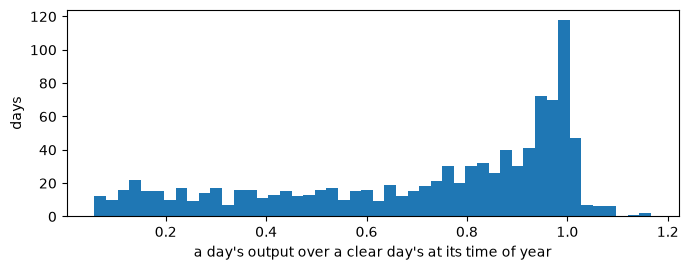

In [13]:
clearness = clear_day.dropna()  # a day's ratio over a clear day's at its time of year
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(clearness.clip(upper=1.2), bins=48, color="C0")
ax.set(xlabel="a day's output over a clear day's at its time of year", ylabel="days")
fig.tight_layout()
clearness.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(3).to_frame("clearness").T

**What it shows.** **Observed:**

- **Not two groups.** One sharp peak of clear days between 0.9 and 1.0, and below it a flat spread all the way down to 0.06, with no second peak
- **Half the days are above 0.82, a quarter below 0.49**

**Learned → design:** there is no natural boundary between cloudy and "in between", only one where the clear peak starts. So three segments, cut at round numbers near the quartiles: clear from 0.9, cloudy under 0.5, mixed between. (A first try at 0.4 and 0.8 was made before the histogram was drawn: it counted as clear 78 days that lie below the peak.)

**Step.** The candidates' error in each segment, by the target day's clearness. The clearness is known only afterwards: this is a way to read results, not an input.

In [14]:
bounds = pd.cut(clearness, [0, 0.5, 0.9, 9], labels=["cloudy, under 0.5", "mixed", "clear, 0.9 up"])
day_of = pd.Series(
    target.loc[error.index, "target_day"].astype("datetime64[ns]"), index=error.index
)
segment = day_of.map(bounds)
by_segment = error[keep].abs().groupby(segment, observed=True).mean()
by_segment.insert(0, "days", day_of.groupby(segment, observed=True).nunique())
by_segment.insert(1, "share_of_days", by_segment["days"] / by_segment["days"].sum())
by_segment.round(3)

,days,share_of_days,"persistence, 2 days back","day ratio, median of 7","slot ratio, median of 7","slot ratio, mean of 7","output, mean of 7"
target_day,,,,,,,
"cloudy, under 0.5",169,0.277,0.167,0.167,0.169,0.153,0.153
mixed,218,0.357,0.117,0.085,0.082,0.068,0.068
"clear, 0.9 up",223,0.366,0.098,0.094,0.081,0.098,0.099


**What it shows.** **Observed:**

- **Roughly a third of days each:** 223 clear, 218 mixed, 169 cloudy
- **On cloudy days nothing helps much:** 15.3% of capacity for the week's mean, 16.7% for persistence
- **On mixed days the week's mean halves the error:** 6.8% against 11.7%
- **On clear days the median of the week is best, 8.1%,** and the mean is no better than persistence (9.8%): a mean is pulled down by the week's cloudy days, a median isn't

**Learned → design:** no rule over past output is best everywhere, because none knows what kind of day tomorrow is. That is what the weather forecast has to add, and where a model can earn its skill: 15% of capacity on cloudy days is the error of not knowing.

## 7. Is forecast radiation in step with the sun?

**Step.** A weather series moved by one slot would not fail anything: the model would only score a little worse. On clear days the forecast's radiation should rise and fall with the sun. The forecast radiation at `T`, weighted over the nine points as clear sky is (`dws_point_weights`), for the model the solar path uses (MSM). Then, for each clear day, the time its profile is centred on, for clear-sky radiation, forecast radiation and output.

The row count per slot is printed because a first version of this query summed every weather model in `dws_weather` and counted 27 rows per slot, not 9. The centres and correlations below don't depend on scale, so they barely moved when it was fixed, but the radiation itself was doubled.

In [15]:
forecast = sql(f"""
SELECT w.target_day AS day, FORMAT_TIMESTAMP('%H:%M', w.slot_start, 'Asia/Tokyo') AS slot,
  SUM(p.weight * w.ghi_w_m2) AS forecast_ghi, COUNT(*) AS points, ANY_VALUE(w.source) AS source
FROM `{DWS}.dws_weather` AS w
INNER JOIN `{DWS}.dws_point_weights` AS p USING (decision_time, point)
WHERE w.model = 'jma_msm'
GROUP BY day, slot
""")
forecast["day"] = pd.to_datetime(forecast["day"])
FORECAST = forecast.pivot(index="day", columns="slot", values="forecast_ghi").reindex(RATIO.index)
CLEAR_GHI = CLEAR_SKY.div(CAPACITY, axis=0) * 1000  # the clear-sky radiation behind clear_sky_mw
print(
    f"forecast radiation for {FORECAST.notna().any(axis=1).sum()} target days; rows per slot: "
    f"{forecast['points'].min()} to {forecast['points'].max()} (nine points, one model)"
)


def centre(profile: pd.DataFrame) -> pd.Series:
    """The time of day a day's profile is centred on, in hours: its mean weighted by its values."""
    values = profile.fillna(0).to_numpy()
    return pd.Series(
        (values * (hours + 0.25)).sum(axis=1) / values.sum(axis=1), index=profile.index
    )


days = clearest.intersection(FORECAST.dropna(how="all").index)
centres = pd.DataFrame(
    {
        "clear_sky": centre(CLEAR_GHI.loc[days]),
        "forecast": centre(FORECAST.loc[days]),
        "output": centre(LABEL.loc[days]),
    }
)
minutes = pd.DataFrame(
    {
        "forecast_minus_clear_sky": (centres["forecast"] - centres["clear_sky"]) * 60,
        "output_minus_clear_sky": (centres["output"] - centres["clear_sky"]) * 60,
        "output_minus_forecast": (centres["output"] - centres["forecast"]) * 60,
    }
)
print(f"{len(days)} clear days")
minutes.describe(percentiles=[0.05, 0.5, 0.95]).round(1).T

[82.9 MB scanned, 0 s in BigQuery]
forecast radiation for 1007 target days; rows per slot: 9 to 9 (nine points, one model)
291 clear days


,count,mean,std,min,5%,50%,95%,max
forecast_minus_clear_sky,291.000,0.300,6.500,-26.000,-7.100,-0.200,11.300,35.100
output_minus_clear_sky,291.000,4.000,4.600,-12.800,-4.900,4.600,10.400,31.100
output_minus_forecast,291.000,3.800,6.700,-34.900,-9.500,4.800,11.800,26.600


**Step.** The same from another side: the correlation between a day's forecast profile and its clear-sky profile, and its output, with the forecast moved by up to two slots either way.

In [16]:
def match(a: pd.DataFrame, b: pd.DataFrame, shift: int) -> float:
    """The mean over days of the correlation between a day's profile in `a` and in `b` moved
    `shift` slots later."""
    moved = b.shift(shift, axis=1)
    both = a.notna() & moved.notna()
    x, y = a.where(both), moved.where(both)
    x, y = x.sub(x.mean(axis=1), axis=0), y.sub(y.mean(axis=1), axis=0)
    return float(((x * y).sum(axis=1) / np.sqrt((x**2).sum(axis=1) * (y**2).sum(axis=1))).mean())


shifts = range(-2, 3)
pd.DataFrame(
    {
        "forecast against clear sky": [
            match(CLEAR_GHI.loc[days], FORECAST.loc[days], s) for s in shifts
        ],
        "forecast against output": [match(LABEL.loc[days], FORECAST.loc[days], s) for s in shifts],
    },
    index=pd.Index([f"forecast moved {s:+d} slots" for s in shifts]),
).round(4)

,forecast against clear sky,forecast against output
forecast moved -2 slots,0.933,0.923
forecast moved -1 slots,0.978,0.973
forecast moved +0 slots,0.993,0.993
forecast moved +1 slots,0.978,0.981
forecast moved +2 slots,0.933,0.938


**What it shows.** **Observed**, on 291 clear days:

- **The forecast is centred with the sun:** 0.3 minutes after clear-sky radiation on average, and within about 10 minutes on nine days of ten. A slot is 30 minutes
- **Output is centred 4 minutes after the sun,** which fits section 2's afternoons holding up longer than mornings build
- **The match is best with no shift:** 0.993, against 0.978 with the forecast one slot either way

**Learned → design:** the weather series are on the right slots. Nothing to change.

## 8. The year-on-year question again, with days the forecast calls clear

**Step.** Section 3 couldn't read single months, because its clear days were picked from output itself. With the forecast loaded, a second try: pick the days the forecast calls clear (its radiation within 3% of the clearest forecasts nearby), and compare their day ratio between years, month by month.

In [17]:
lit_slots = RATIO.notna()
forecast_ratio = FORECAST.where(lit_slots).sum(axis=1) / CLEAR_GHI.where(lit_slots).sum(axis=1)
forecast_ratio = forecast_ratio.where(lit_slots.sum(axis=1) >= 8)
# A day the forecast calls clear: its forecast radiation within 3% of the clearest forecasts nearby
called_clear = forecast_ratio / nearby(forecast_ratio.to_frame("f"))["f"].quantile(0.9) >= 0.97
picked_days = by_day[called_clear.reindex(by_day.index).to_numpy()]
table = picked_days.groupby([picked_days.index.month, picked_days.index.year]).agg(["mean", "size"])
ratio_by_year = table["mean"].unstack().rename_axis("month")
days_by_year = table["size"].unstack().rename_axis("month")
ratio_by_year.columns = ratio_by_year.columns.astype(str)
ratio_by_year["2025_over_2024"] = ratio_by_year["2025"] / ratio_by_year["2024"]
ratio_by_year["2026_over_2025"] = ratio_by_year["2026"] / ratio_by_year["2025"]
display(ratio_by_year.round(3).join(days_by_year.add_prefix("days_")))
change = ratio_by_year[["2025_over_2024", "2026_over_2025"]].stack()
print(
    f"{len(picked_days)} days the forecast calls clear; their output over clear sky, year on year: "
    f"mean {change.mean():.3f}, from {change.min():.3f} to {change.max():.3f} over "
    f"{change.count()} month pairs; standard deviation {change.std():.3f}"
)

day,2024,2025,2026,2025_over_2024,2026_over_2025,days_2024,days_2025,days_2026
month,,,,,,,,
1,NaN,1.101,1.096,NaN,0.995,NaN,16.000,17.000
2,0.983,1.034,0.967,1.051,0.935,2.000,8.000,9.000
3,0.918,0.855,0.925,0.932,1.081,12.000,10.000,8.000
4,0.768,0.762,0.805,0.992,1.057,8.000,10.000,5.000
5,0.769,0.653,0.753,0.849,1.153,8.000,5.000,8.000
6,0.669,0.615,0.655,0.920,1.065,6.000,6.000,5.000
7,0.598,0.673,0.623,1.125,0.926,4.000,4.000,6.000
8,0.632,0.683,0.555,1.081,0.812,4.000,7.000,6.000
9,0.652,0.706,0.657,1.083,0.931,4.000,8.000,3.000


249 days the forecast calls clear; their output over clear sky, year on year: mean 0.999, from 0.812 to 1.153 over 22 month pairs; standard deviation 0.090


**What it shows.** **Observed**, on 249 such days:

- **The mean agrees with section 3:** 0.999 a year on the last
- **The months are no steadier, they are worse:** from 0.81 to 1.15, a standard deviation of 0.090. Most months have under ten such days, and a forecast of clear sky is not a clear day

**Learned → design:** two ways of picking clear days, two means within half a percent of 1, and neither reads a single month. The clear-day ratio shows no drift over three years, to within one or two percent a year. A slower drift than that can't be seen yet.

## What this exploration made known

| We assumed | We found | So |
| --- | --- | --- |
| On a clear day output is close to clear-sky output, apart from a shape error from panel tilt | A clear noon gives 1.19 times flat-panel clear sky in January and 0.72 in July; mornings and evenings sit far below midday all year (sections 1, 2) | Clear-sky output is a rough yardstick. A model reads it with the hour and the time of year, never alone |
| One recent ratio a day is enough for the simple baseline | Even a clear day's own ratio, known in hindsight, misses by 4.0% of capacity; on forecasts a ratio per slot scores 10.6% against 11.1% (sections 2, 5) | Anything built on a ratio uses one per slot |
| The clear-day ratio is roughly steady over the years | No drift: 0.995 and 0.999 a year by two ways of picking clear days. Single months can't be read either way (sections 3, 8) | All three years serve as training data; no reason yet to drop the oldest |
| Predicting MW would clip, since a tree can't go above what it trained on and capacity grows | Against two fixed years, 40 slots of 2026 are out of range. For a model retrained monthly, 23 slots on 8 days, by 3.4% of capacity at most, in spring (section 4) | The model predicts output over capacity, not MW: it costs nothing and removes the clipping. Dividing by clear sky is tried against it in the backtest |
| Clear sky × the 7-day median ratio is the baseline to add beside persistence | The gain is from the week, not the clear sky: the plain mean of the same slot over 7 days scores 10.3%, the same as the ratio's mean, and the mean beats the median in 16 folds of 20, without its bias (section 5) | **The second baseline is the mean of the same slot's output over the last seven complete days,** read as known at `T`, curtailed output added. It beats persistence in all 20 folds (skill 0.17). The ratio form gets no place of its own |
| Days fall into clear and cloudy | One peak of clear days and a flat spread below it (section 6) | Three segments by a day's clearness: clear from 0.9, mixed, cloudy under 0.5, about a third of days each |
| (Not asked beforehand) Which days the baselines fail on | Cloudy days: 15 to 17% of capacity whatever rule is used. Clear days: the week's median, 8.1%, beats its mean, 9.8% (section 6) | What is left to gain is knowing tomorrow's kind of day: the weather forecast's job, and the first thing to look for in a model's results by segment |
| Forecast radiation sits on the right slots | Centred within a minute of the sun on average; the best match is with no shift (section 7) | Nothing to change |

## Still open

| What | Why it can't be known yet | When |
| --- | --- | --- |
| Whether the model's target is output over capacity or over clear-sky output | A modelling choice: this notebook shows only that MW is the wrong one | The first backtest of the model |
| Why a clear summer noon gives only 0.72 of flat-panel clear sky | Heat, humid air and panel tilt all point the same way, and nothing here separates them | If the model's summer errors ask for it |
| A drift in the clear-day ratio slower than one or two percent a year | Three years, and months that can't be read one by one | Each further year |
| What a clear day gives in a month with no clear day | The 90th percentile of 29 days is not a clear day in the rainy season, so clearness is overstated there | If the segments' results look odd in June and July |

## Where the sources and the data disagree

| Where | Says | We found | Handled by |
| --- | --- | --- | --- |
| [Phase-1 plan](../docs/phase1/README.md#model-and-evaluation), Baselines | *"Clear-sky × recent ratio: clear-sky output for D × the 7-day median ratio"* | The same forecast as the plain 7-day mean of output, and the mean beats the median (section 5) | The plan's baseline becomes the 7-day mean of output per slot |
| The same table, Inputs | *"the median of actual over clear-sky for the last 7 complete days"* | One ratio a day misses the day's shape; per slot, the mean of output does as well without clear sky (sections 2, 5) | The input becomes the 7-day mean of output per slot; clear-sky output stays an input of its own |
| The same table, Segments | *"Clear vs cloudy days (by clear-sky index)"* | No two groups: a clear peak and a flat spread (section 6) | Three segments, by clearness against a clear day at that time of year |
| [Phase-1 plan](../docs/phase1/README.md#decisions), Clear-sky output | *"A constant error in scale cancels in the ratio baseline and doesn't matter to tree models; the likely error in shape, panel tilt, is for notebook 09 to measure"* | The error is not constant: 0.72 to 1.19 by season, and bent through the day (section 2) | Measured here; the model gets the hour and the time of year beside clear sky |

## Sources

| Page | Supports |
| --- | --- |
| [Notebook 05](05_clear_sky.ipynb) | Clear-sky output: flat panels, a radiation that depends only on the sun's position |
| [Notebook 08](08_solar_label.ipynb), sections 3.3 and 3.4 | The label; lit slots; the clear-day level as the 90th percentile of the days nearby; bright days stepping more than dull ones |
| [Notebook 04](04_ods_to_dwd.ipynb), section 5.3 | Two days back as the newest complete day at `T` |
| [Phase-1 plan](../docs/phase1/README.md), Model and evaluation, and Decisions | The proposed baselines, inputs, segments and retraining cadence |